<h4>Reflective Self-Correcting Code Generation AI Agent</h4>

## Setup Environment Variables

In [30]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

## Build Code Generator

In [31]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field

In [32]:
# Initialize GPT-4o
llm = ChatOpenAI(model_name="gpt-4o", temperature=0)

In [33]:
CODE_GEN_SYS_PROMPT = [
        (
            "system",
            """You are a coding assistant.
                Ensure any code you provide can be executed with all required imports and variables defined.
                Make sure point 3 below has some code to run and execute any code or functions which you define

                Structure your answer as follows:
                  1) a prefix describing the code solution
                  2) the imports (if no imports needed keep it empty string)
                  3) the functioning code blocks

                Here is the user question:""",
        )
]
# Data model
class Code(BaseModel):
    """Schema for code solutions to questions about coding."""

    prefix: str = Field(description="Description of the problem and approach")
    imports: str = Field(description="Just the import statements of the code")
    code: str = Field(description="Code blocks not including import statements")

# LLM
code_generator = llm.with_structured_output(Code)

In [34]:
question = "How to create fibonacci series"
messages = [("user", question)]

result = code_generator.invoke(CODE_GEN_SYS_PROMPT + messages)
result

Code(prefix="To create a Fibonacci series, we can use a simple iterative approach. The Fibonacci sequence is a series of numbers where each number is the sum of the two preceding ones, usually starting with 0 and 1. Here's a Python function to generate the Fibonacci series up to a specified number of terms.", imports='', code='def fibonacci_series(n):\n    fib_sequence = []\n    a, b = 0, 1\n    for _ in range(n):\n        fib_sequence.append(a)\n        a, b = b, a + b\n    return fib_sequence\n\n# Example usage:\nnum_terms = 10\nprint(f"Fibonacci series with {num_terms} terms:", fibonacci_series(num_terms))')

In [35]:
for key, value in result:
     print(f"{key}: \n {value}\n")

prefix: 
 To create a Fibonacci series, we can use a simple iterative approach. The Fibonacci sequence is a series of numbers where each number is the sum of the two preceding ones, usually starting with 0 and 1. Here's a Python function to generate the Fibonacci series up to a specified number of terms.

imports: 
 

code: 
 def fibonacci_series(n):
    fib_sequence = []
    a, b = 0, 1
    for _ in range(n):
        fib_sequence.append(a)
        a, b = b, a + b
    return fib_sequence

# Example usage:
num_terms = 10
print(f"Fibonacci series with {num_terms} terms:", fibonacci_series(num_terms))



## Build Agent Graph Node Functions

### Create Agent State Schema

In [36]:
from typing import TypedDict, Annotated, List
from langgraph.graph.message import AnyMessage, add_messages
from langchain_core.messages import HumanMessage
class CodeGenState(TypedDict):
    """
    Represents the state of our graph.

    Attributes:
        error_flag : Binary flag for control flow to indicate whether test error was tripped
        messages : With user question, error messages, reasoning
        code_solution : Code solution
        attempts : Number of tries
    """
    error_flag: str
    messages: Annotated[List[AnyMessage], add_messages]
    code_solution: str
    attempts: int

Node 1: Generate Code

In [37]:
def generate_code(state: CodeGenState) -> CodeGenState:
    """Generate code solution from GPT-4o, structured as prefix/imports/code."""
    print("--- GENERATING CODE SOLUTION ---")
    msgs = state["messages"]
    attempts_so_far = state["attempts"]

    # Call code_generation_chain
    code_soln = code_generator.invoke(CODE_GEN_SYS_PROMPT + msgs)

    # We'll record the chain's answer as a new assistant message in conversation.
    new_msg_content = (f"Here is my solution attempt:\n\nDescription: {code_soln.prefix}\n\n"
                       f"Imports: {code_soln.imports}\n\n"
                       f"Code:\n{code_soln.code}")

    msgs.append(("assistant", new_msg_content))
    attempts_so_far += 1

    return {
        "messages": msgs,
        "code_solution": code_soln,
        "attempts": attempts_so_far
    }

### Node 2: Check Code

We try to `exec` the imports, then `exec` the code. If errors occur, we pass them back to the conversation. Otherwise, success.

In [38]:
def check_code_execution(state: CodeGenState) -> CodeGenState:
    print("--- CHECKING CODE EXECUTION ---")
    msgs = state["messages"]
    code_soln = state["code_solution"]
    imports_str = code_soln.imports
    code_str = code_soln.code
    attempts = state["attempts"]

    # Attempt to import:
    try:
        exec(imports_str)
    except Exception as e:
        # Import failed
        print("---CODE IMPORT CHECK: FAILED---")
        error_msg = f"""Import test failed!
                        Here is the exception trace details:
                        {e}.

                        Please fix the import section."""

        msgs.append(("user", error_msg))
        return {
            "code_solution": code_soln,
            "attempts": attempts,
            "messages": msgs,
            "error_flag": "yes"
        }

    # Attempt to run code:
    try:
        scope = {}
        exec(f"{imports_str}\n{code_str}", scope)
    except Exception as e:
        print("---CODE BLOCK CHECK: FAILED---")
        error_msg =  f"""Your code solution failed the code execution test!
                            Here is the exception trace details:
                            {e}

                            Reflect on this error and your prior attempt to solve the problem.

                            (1) State what you think went wrong with the prior solution
                            (2) try to solve this problem again.

                            Return the FULL SOLUTION.

                            Use the code tool to structure the output with a prefix, imports, and code block."""

        msgs.append(("user", error_msg))
        return {
            "code_solution": code_soln,
            "attempts": attempts,
            "messages": msgs,
            "error_flag": "yes"
        }

    # If no errors:
    print("--- NO ERRORS FOUND ---")
    return {
            "code_solution": code_soln,
            "attempts": attempts,
            "messages": msgs,
            "error_flag": "no"
    }

### Conditional Routing to Decide Next Step

In [39]:
MAX_ATTEMPTS = 3

def decide_next(state: CodeGenState) -> str:
    """If error or attempts < MAX_ATTEMPTS => go generate. Else end."""
    err = state["error_flag"]
    attempts = state["attempts"]
    if err == "no" or attempts >= MAX_ATTEMPTS:
        print("--- DECISION: FINISH ---")
        return "end"
    else:
        print("--- DECISION: RETRY ---")
        return "generate_code"

Build the Reflection Agentic Graph

In [40]:
from langgraph.graph import StateGraph, END
from langchain_core.messages import HumanMessage

graph = StateGraph(CodeGenState)

# Add nodes:
graph.add_node("generate_code", generate_code)
graph.add_node("check_code", check_code_execution)

# Edges:
graph.set_entry_point("generate_code")
graph.add_edge("generate_code", "check_code")
graph.add_conditional_edges(
    "check_code",
    decide_next,
    {
        "generate_code": "generate_code",
        "end": END
    }
)

coder_agent = graph.compile()

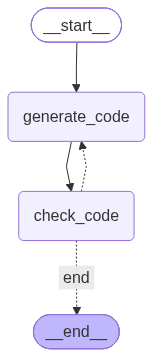

In [41]:
from IPython.display import display, Image, Markdown

display(Image(coder_agent.get_graph().draw_mermaid_png()))

Run and Test the Agent

In [42]:
from langchain_core.messages import HumanMessage

def call_reflection_coding_agent(agent, prompt, verbose=False):
    events = agent.stream(
        {"messages": [HumanMessage(content=prompt)], "attempts": 0},
        stream_mode="values",
    )

    print('Running Agent. Please wait...')
    for event in events:
        if verbose:
            event["messages"][-1].pretty_print()

    print('\n\nFinal Solution:')
    print("\nDescription:\n" + event["code_solution"].prefix +
          "\nCode:\n"+event["code_solution"].imports + '\n\n' + event["code_solution"].code)

In [29]:
prompt = """Give me working code to get data from Twitter using API"""
call_reflection_coding_agent(coder_agent, prompt, verbose=True)

Running Agent. Please wait...
================================ Human Message =================================

Give me working code to get data from Twitter using API
--- GENERATING CODE SOLUTION ---
================================== Ai Message ==================================

Here is my solution attempt:

Description: To access data from Twitter using their API, you need to use the Tweepy library, which is a Python wrapper for the Twitter API. First, you need to create a Twitter Developer account and set up a project to get your API keys and tokens. Once you have these credentials, you can use Tweepy to authenticate and fetch data from Twitter. Below is an example of how to authenticate and fetch the latest tweets from a user's timeline.

Imports: import tweepy

Code:
# Replace these with your own credentials
API_KEY = 'your_api_key'
API_SECRET_KEY = 'your_api_secret_key'
ACCESS_TOKEN = 'your_access_token'
ACCESS_TOKEN_SECRET = 'your_access_token_secret'

# Authenticate to Twitte